# 01 - Quickstart: three policies on a toy pool

**The situation.** You have a model, a pool of 6,000 candidate compounds, and
room for 96 wells per round. You can run six rounds. Which 96 do you pick?

The default answer is *greedy*: take the 96 highest predictions. This notebook
shows what greedy costs you, using a synthetic pool where we know every answer
in advance so we can score the choices.

**What you will see:** greedy wins the first few rounds decisively, then its
productivity collapses, because it has spent every well confirming what the
model already believed.

In [1]:
import sys
from pathlib import Path

# Figures and tables land in results/ so the committed notebooks and the README
# reference the same files.
ROOT = Path.cwd()
if not (ROOT / "loopwise").exists():
    ROOT = ROOT.parent
FIGDIR = ROOT / "results" / "figures"
TABDIR = ROOT / "results" / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)
print("loopwise", __import__("loopwise").__version__, "| figures ->", FIGDIR)

loopwise 0.1.0 | figures -> /home/user/loopwise/results/figures


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

from loopwise import Campaign, available_policies
from loopwise.datasets import make_synthetic_pool
from loopwise.replay import compare_policies, plot_comparison

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("policies available:", available_policies())

policies available: ['random', 'greedy', 'uncertainty', 'bald', 'expected_model_change', 'diversity', 'kdpp', 'thompson', 'hybrid']


## The pool

Two properties of this synthetic pool are deliberate, because they are what
make real screening hard:

1. **Compounds come in clusters.** Real libraries are built from analogue
   series -- dozens of variations on one scaffold. This is why a diversity
   constraint can matter: the top 96 by any score are often near-duplicates,
   so you have bought one measurement 96 times.
2. **The hit rate is 5%.** Activity depends on a few features plus noise. At
   this rate, a greedy batch that finds 20 hits looks like a triumph while
   teaching the model almost nothing.

In [3]:
pool, info = make_synthetic_pool(
    n_items=6000, n_features=20, hit_rate=0.05, n_clusters=12, seed=0
)
feature_cols = info["feature_cols"]
truth = dict(zip(pool["item_id"], pool["label"], strict=True))

print(f"{info['n_compounds']} compounds, {info['n_actives']} actives "
      f"({info['hit_rate']:.1%} hit rate), {info['n_clusters']} structural clusters")
print(f"activity depends on features {info['informative_features']} of 20")
pool[["item_id", "cluster", "label"] + feature_cols[:4]].head()

6000 compounds, 300 actives (5.0% hit rate), 12 structural clusters
activity depends on features [10, 13, 15, 19] of 20


,item_id,cluster,label,f0,f1,f2,f3
0,CPD00000,5,0,1.326541,2.125217,0.020110,-2.995597
1,CPD00001,7,0,1.909308,1.189324,0.419712,1.845895
2,CPD00002,9,0,-0.891906,-2.908889,2.041829,0.066529
3,CPD00003,7,0,0.801226,1.005545,1.332627,1.573865
4,CPD00004,5,0,-0.705645,1.205375,-0.382514,-3.346423


## Driving one campaign by hand

This is the whole API. `select()` returns the rows to run plus *why each was
chosen*; `observe()` feeds measurements back; `report()` summarizes.

Note what the `pool` we hand to `Campaign` does **not** contain: the `label`
column. The campaign is blind, exactly as it would be in a lab, and we play the
role of the assay by looking answers up in `truth`.

In [4]:
blind_pool = pool.drop(columns=["label", "latent_activity"])

campaign = Campaign(
    pool=blind_pool,
    model=RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    budget=96,
    policy="hybrid",
    feature_cols=feature_cols,
    id_col="item_id",
    n_rounds_planned=6,
    seed=0,
)

batch = campaign.select()
print(batch.explain())

Round 1: 96 compound(s) selected by policy 'diversity (seeding)'.
Selecting 96 compound(s); binding constraint: well budget.
Requested budget 96; well budget 96; 80 usable wells per plate.
Estimated cost: 96 compounds in 96 wells on 2 plate(s): 0.00 acquisition + 0.00 plate = 0.00 USD
Cost: 96 compounds in 96 wells on 2 plate(s): 0.00 acquisition + 0.00 plate = 0.00 USD
96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
96 sample wells across 2 plate(s); controls intact: True.
Edge wells are 25% of available sample wells; highest-score stratum edge enrichment vs chance 1.0 (balanced). With 96 samples in 4 strata this ratio is coarse -- one well either way moves it noticeably.


Round 1 used the **seeding policy**, not the hybrid policy we asked for. With
no measurements there is nothing to train on, so there is no model to exploit
and no uncertainty to explore -- the only sensible objective is to cover the
feature space. Loopwise does that automatically and tells you it did, rather
than fitting a model to nothing.

### Why each compound was chosen

The reason columns are the point. Six months from now, "why was this compound
on my plate?" is answerable from this CSV alone.

In [5]:
cols = ["item_id", "rank", "posterior_mean", "posterior_std", "reason"]
batch.frame[cols].head(5).style.set_properties(subset=["reason"], **{"width": "520px"})

,item_id,rank,posterior_mean,posterior_std,reason
3165,CPD03165,1,0.000000,0.000000,"pick 1/96 by facility_location: marginal gain 675.4, predicted score 0.0000, max similarity to an earlier pick 0.000"
5744,CPD05744,2,0.000000,0.000000,"pick 2/96 by facility_location: marginal gain 479.1, predicted score 0.0000, max similarity to an earlier pick -0.149"
3044,CPD03044,3,0.000000,0.000000,"pick 3/96 by facility_location: marginal gain 474.1, predicted score 0.0000, max similarity to an earlier pick -0.345"
2557,CPD02557,4,0.000000,0.000000,"pick 4/96 by facility_location: marginal gain 323.3, predicted score 0.0000, max similarity to an earlier pick -0.002"
5751,CPD05751,5,0.000000,0.000000,"pick 5/96 by facility_location: marginal gain 297.5, predicted score 0.0000, max similarity to an earlier pick 0.087"


In [6]:
# Play the assay: look up the true labels for the selected compounds.
results = pd.DataFrame({
    "item_id": batch.frame["item_id"],
    "label": [truth[i] for i in batch.frame["item_id"]],
})
campaign.observe(results)
print(f"round 1: {int(results['label'].sum())} hits in {len(results)} wells "
      f"({results['label'].mean():.1%})")

round 1: 5 hits in 96 wells (5.2%)


In [7]:
# Rounds 2-6.
for _ in range(5):
    batch = campaign.select()
    results = pd.DataFrame({
        "item_id": batch.frame["item_id"],
        "label": [truth[i] for i in batch.frame["item_id"]],
    })
    campaign.observe(results)
    alpha = batch.diagnostics.get("alpha")
    print(f"round {batch.round_index + 1}: {int(results['label'].sum()):>3} hits "
          f"({results['label'].mean():>5.1%})"
          + (f", alpha={alpha:.2f}" if alpha else ""))

round 2:  49 hits (51.0%), alpha=0.50


round 3:  65 hits (67.7%), alpha=0.60


round 4:  93 hits (96.9%), alpha=0.70


round 5:  56 hits (58.3%), alpha=0.80


round 6:  19 hits (19.8%), alpha=0.90


## The report

`report()` gives the three things worth tracking. Passing `oracle_labels` is
only possible here because this is a simulation -- in a live campaign you do
not know the answers, and Loopwise says so instead of inventing a regret curve.

**Regret** is how many hits a perfectly informed oracle would have found by now
minus how many you did find.

**Calibration drift** is the one people forget. Every round, the model is
retrained on a sample *it chose itself* -- the opposite of a random sample. That
bends calibration predictably: a model fed its own confident picks becomes
over-confident. Expected calibration error (ECE) catches this while accuracy
does not.

**Batch diversity** is mean pairwise distance within the batch, in units of the
pool's own spread. 1.0 means "as spread out as two random compounds"; 0.4 means
you bought a lot of near-duplicates.

In [8]:
report = campaign.report(oracle_labels=truth)
print(report.summary())

6 round(s), 576 compounds measured, 287 hit(s).
Hit rate by round: R1=5.2%, R2=51.0%, R3=67.7%, R4=96.9%, R5=58.3%, R6=19.8%
Cumulative hits: [5, 54, 119, 212, 268, 287]
Fraction of achievable hits found: 95.7%
Calibration error (ECE) 0.052 -> 0.260 (worsening).
Batch diversity (1.0 = two random pool members): R1=0.97, R2=0.33, R3=0.35, R4=0.32, R5=0.34, R6=0.45
Hybrid alpha by round: R2=0.50, R3=0.60, R4=0.70, R5=0.80, R6=0.90
Regret is measured against an oracle that knows every label: 300 actives exist in the pool. This is only possible in a retrospective replay.


In [9]:
show = ["round", "n_hits", "hit_rate", "cumulative_hits", "oracle_cumulative_hits",
        "cumulative_regret", "mean_predicted", "observed_hit_rate", "ece",
        "batch_diversity", "alpha"]
report.frame[show].round(3)

,round,n_hits,hit_rate,cumulative_hits,oracle_cumulative_hits,cumulative_regret,mean_predicted,observed_hit_rate,ece,batch_diversity,alpha
0,1,5,0.052,5,96,91,0.000,0.052,0.052,0.967,NaN
1,2,49,0.510,54,192,138,0.522,0.510,0.011,0.334,0.5
2,3,65,0.677,119,288,169,0.543,0.677,0.134,0.347,0.6
3,4,93,0.969,212,300,88,0.814,0.969,0.155,0.320,0.7
4,5,56,0.583,268,300,32,0.640,0.583,0.077,0.336,0.8
5,6,19,0.198,287,300,13,0.436,0.198,0.260,0.447,0.9


Look at `mean_predicted` against `observed_hit_rate`. Where predictions run
above the observed rate, the model is over-confident about the batch it chose
-- the selection-bias effect, visible in the numbers.

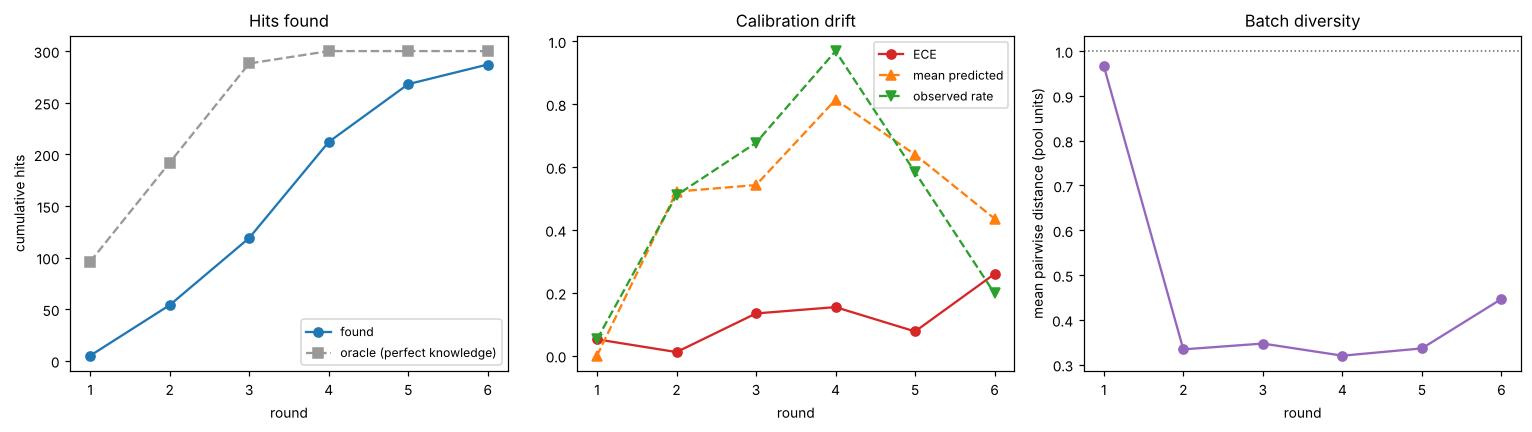

In [10]:
fig = report.plot()
FIGDIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGDIR / "01_hybrid_campaign_report.png", dpi=150, bbox_inches="tight")

## Three policies, head to head

One campaign tells you nothing about whether the policy was good -- you have no
counterfactual. The replay harness runs the same pool and the same model under
different policies, hiding all labels and revealing only selected batches.

Three seeds, because the spread between seeds is often as large as the gap
between policies. The shaded bands are the min-max envelope: **a gap smaller
than the bands is not a result.**

In [11]:
long_frame, results = compare_policies(
    pool.drop(columns=["latent_activity"]),
    label_col="label",
    model_factory=lambda: RandomForestClassifier(
        n_estimators=200, random_state=0, n_jobs=-1
    ),
    policies=["random", "greedy", "bald", "hybrid"],
    seeds=(0, 1, 2),
    feature_cols=feature_cols,
    id_col="item_id",
    budget=96,
    n_rounds=6,
    n_initial_labels=96,
    verbose=True,
)

[replay] policy=random seed=0


   random: 28/247 actives (11.3%) after 6 rounds of 96; final PR-AUC 0.797; rounds to 50% of actives: not reached; 6.5s
[replay] policy=random seed=1


   random: 45/245 actives (18.4%) after 6 rounds of 96; final PR-AUC 0.854; rounds to 50% of actives: not reached; 6.4s
[replay] policy=random seed=2


   random: 22/243 actives (9.1%) after 6 rounds of 96; final PR-AUC 0.894; rounds to 50% of actives: not reached; 6.6s
[replay] policy=greedy seed=0


   greedy: 236/247 actives (95.5%) after 6 rounds of 96; final PR-AUC 0.871; rounds to 50% of actives: 2; 6.5s
[replay] policy=greedy seed=1


...

   bald: 236/245 actives (96.3%) after 6 rounds of 96; final PR-AUC 0.950; rounds to 50% of actives: 3; 6.6s
[replay] policy=bald seed=2


   bald: 226/243 actives (93.0%) after 6 rounds of 96; final PR-AUC 0.986; rounds to 50% of actives: 3; 6.5s
[replay] policy=hybrid seed=0


   hybrid: 234/247 actives (94.7%) after 6 rounds of 96; final PR-AUC 0.934; rounds to 50% of actives: 3; 7.1s
[replay] policy=hybrid seed=1


   hybrid: 238/245 actives (97.1%) after 6 rounds of 96; final PR-AUC 0.962; rounds to 50% of actives: 3; 6.7s
[replay] policy=hybrid seed=2


   hybrid: 235/243 actives (96.7%) after 6 rounds of 96; final PR-AUC 0.985; rounds to 50% of actives: 2; 6.6s


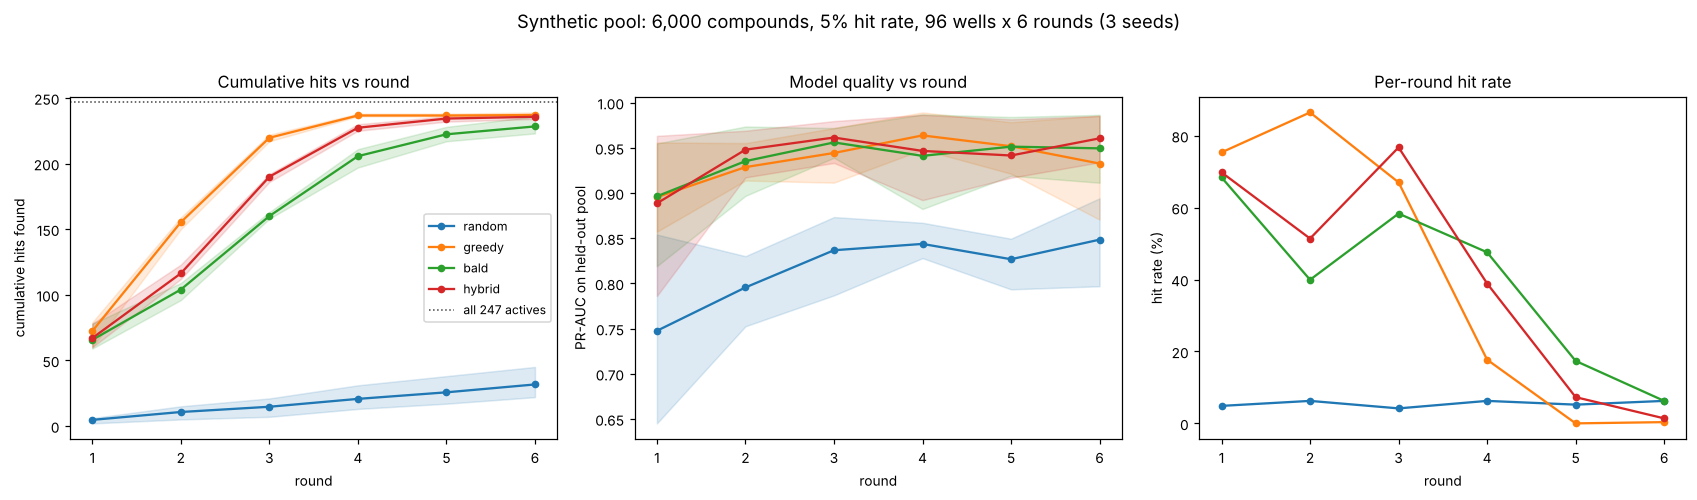

In [12]:
n_actives = results["greedy"][0].n_actives
fig = plot_comparison(
    long_frame,
    n_actives=n_actives,
    title="Synthetic pool: 6,000 compounds, 5% hit rate, 96 wells x 6 rounds (3 seeds)",
)
fig.savefig(FIGDIR / "01_policy_comparison.png", dpi=150, bbox_inches="tight")

In [13]:
final = long_frame[long_frame["round"] == long_frame["round"].max()]
summary = final.groupby("policy").agg(
    cumulative_hits=("cumulative_hits", "mean"),
    hits_sd=("cumulative_hits", "std"),
    fraction_found=("fraction_of_achievable", "mean"),
    final_pr_auc=("pr_auc", "mean"),
    pr_auc_sd=("pr_auc", "std"),
).round(3).sort_values("cumulative_hits", ascending=False)
summary

,cumulative_hits,hits_sd,fraction_found,final_pr_auc,pr_auc_sd
policy,,,,,
greedy,237.000,1.732,0.967,0.933,0.058
hybrid,235.667,2.082,0.962,0.960,0.026
bald,228.333,6.807,0.932,0.949,0.038
random,31.667,11.930,0.129,0.848,0.049


## The regret curve, and the thing it hides

Cumulative hits is the number a project leader asks for. It also hides the
mechanism, so look at the *per-round* hit rate: that is where the plateau lives.

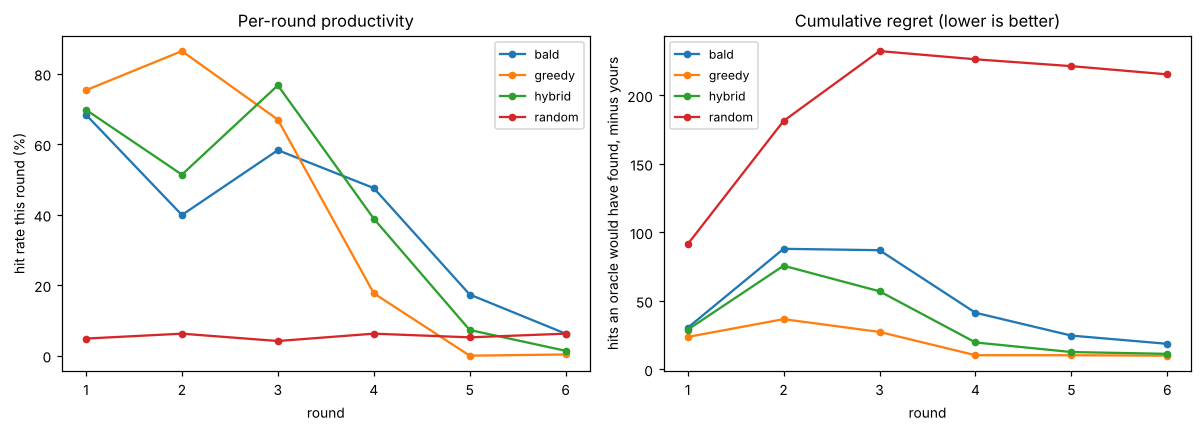

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for policy, group in long_frame.groupby("policy"):
    per_round = group.groupby("round")
    axes[0].plot(per_round["hit_rate"].mean().index,
                 per_round["hit_rate"].mean() * 100, "o-", label=policy, ms=4)
axes[0].set_xlabel("round"); axes[0].set_ylabel("hit rate this round (%)")
axes[0].set_title("Per-round productivity"); axes[0].legend(fontsize=8)

for policy, group in long_frame.groupby("policy"):
    per_round = group.groupby("round")["cumulative_hits"].mean()
    oracle = np.minimum(np.arange(1, len(per_round) + 1) * 96, n_actives)
    axes[1].plot(per_round.index, oracle - per_round.to_numpy(), "o-", label=policy, ms=4)
axes[1].set_xlabel("round"); axes[1].set_ylabel("hits an oracle would have found, minus yours")
axes[1].set_title("Cumulative regret (lower is better)"); axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "01_regret_curves.png", dpi=150, bbox_inches="tight")

## Saturation: why this toy problem flatters everything

Look at the per-round hit rate. Every model-driven policy collapses to near
zero by round 5 -- not because the policies failed, but because they *ran out
of actives to find*. By round 5 they have each found roughly 230 of the 247
actives in the pool.

Two things cause that here, and it is worth separating them:

1. **The problem is easy.** Activity depends on three features through a linear
   rule plus noise, so a random forest reaches PR-AUC ~0.95 within two rounds.
   Once the model is nearly perfect, *every* policy that uses it picks nearly
   the same compounds, and the choice of policy stops mattering.
2. **The budget is not small relative to what there is to find.** 576 wells is
   under 10% of the pool, but the actives are concentrated in a few clusters,
   so a tenth of the pool is more than enough to sweep them up.

This is exactly the regime where active learning does **not** earn its
complexity, and a toy pool is the easiest place in the world to accidentally
demonstrate a policy "winning" under these conditions. Treat the ranking above
as a check that the plumbing works, not as evidence.

The next notebook runs the same comparison on real measured screening data,
where the model tops out at PR-AUC ~0.53 and nothing saturates.